# ЛР №1. Сегментация аномалий на аэроснимках полей (Agriculture-Vision)

Трек А, вариант 3 «Сегментация изображений», предметная область — сельское хозяйство.

Сравниваются три архитектуры: **U-Net + ResNet-50**, **UPerNet + ConvNeXt-Tiny**, **DPT + DINOv3 ViT-S/16**.

## Окружение

Только для Google Colab: загрузка кода из репозитория и недостающих библиотек (PyTorch в Colab уже есть). Локально ячейка ничего не делает.

In [ ]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_URL = "<ссылка на репозиторий>"
    if not Path("/content/lr1").exists():
        !git clone -q {REPO_URL} /content/lr1
    %cd /content/lr1
    !pip install -q segmentation-models-pytorch==0.5.0 timm==1.0.30

Импорты, фиксация seed, проверка GPU.

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src import bench, config as C, data, metrics, models, train, viz

train.seed_everything(C.SEED)
DEVICE = "cuda"
WORKERS = 2 if C.IN_COLAB else 4
pd.set_option("display.precision", 4)
C.OUT_DIR.mkdir(parents=True, exist_ok=True)

print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))
print("данные:", C.DATA_ROOT)

torch 2.14.0+cu130 | GPU: NVIDIA GeForce RTX 4070
данные: D:\nn\labs\datasets\agriculture-vision


## Данные

Загрузка архива (21 ГБ) и манифеста полей из официального хранилища AWS с распаковкой. Если данные уже распакованы, шаг пропускается.

In [3]:
data.prepare_dataset()

Полнота файлов. У каждого снимка должны быть RGB, NIR, граница поля (`boundaries`), маска валидных пикселей (`masks`) и маски 9 типов аномалий. Разметка официального `test` не опубликована.

In [4]:
completeness = {s: data.check_completeness(s)[1] for s in ["train", "val", "test"]}
pd.concat(completeness, axis=1)

train                                val                 \
                     files missing_vs_rgb extra_vs_rgb  files missing_vs_rgb   
rgb                  56944              0            0  18334              0   
nir                  56944              0            0  18334              0   
boundary             56944              0            0  18334              0   
mask                 56944              0            0  18334              0   
double_plant         56944              0            0  18334              0   
drydown              56944              0            0  18334              0   
endrow               56944              0            0  18334              0   
nutrient_deficiency  56944              0            0  18334              0   
planter_skip         56944              0            0  18334              0   
water                56944              0            0  18334              0   
waterway             56944              0            0  18334              0   
weed_cluster         56944              0            0  18334              0   
storm_damage         56944              0            0  18334              0   

                                   test                              
                    extra_vs_rgb  files missing_vs_rgb extra_vs_rgb  
rgb                            0  19708              0            0  
nir                            0  19708              0            0  
boundary                       0  19708              0            0  
mask                           0  19708              0            0  
double_plant                   0      0          19708            0  
drydown                        0      0          19708            0  
endrow                         0      0          19708            0  
nutrient_deficiency            0      0          19708            0  
planter_skip                   0      0          19708            0  
water                          0      0          19708            0  
waterway                       0      0          19708            0  
weed_cluster                   0      0          19708            0  
storm_damage                   0      0          19708            0

Индекс снимков. Имя файла — `<код полёта>_<x1>-<y1>-<x2>-<y2>`; поле, к которому относится полёт, берётся из манифеста `data_manifest.csv`.

In [5]:
index = data.build_index()
index.groupby("official_split").agg(
    images=("id", "size"), flights=("flightcode", "nunique"), fields=("field", "nunique")
)

,images,flights,fields
official_split,,,
train,56944,1950,1411
val,18334,656,572


## Анализ качества данных

Один проход по всем размеченным снимкам: маски сводятся в кэш (16-битная маска: бит k — класс k, бит 15 — невалидный пиксель) и собирается статистика по каждому снимку.

In [6]:
stats = index.merge(data.build_label_cache(index), on="id")
split_of = stats.official_split
stats.shape

(75278, 32)

Форматы изображений.

In [7]:
stats.groupby(["official_split", "rgb_shape", "nir_shape"]).size()

official_split  rgb_shape      nir_shape 
train           (512, 512, 3)  (512, 512)    56944
val             (512, 512, 3)  (512, 512)    18334
dtype: int64

Невалидные пиксели (вне границы поля или отмеченные в `masks`). В обучении и метриках не участвуют.

In [8]:
invalid_share = 1 - stats.px_valid / C.IMG_SIZE**2
pd.DataFrame({
    "доля невалидных пикселей": invalid_share.groupby(split_of).mean(),
    "снимков без валидных пикселей": (stats.px_valid == 0).groupby(split_of).sum(),
    "снимков с >50% невалидных": (invalid_share > 0.5).groupby(split_of).sum(),
})

,доля невалидных пикселей,снимков без валидных пикселей,снимков с >50% невалидных
official_split,,,
train,0.0928,0,1899
val,0.0934,0,718


Распределение классов: доля валидных пикселей класса и доля снимков, на которых класс присутствует. Сумма долей пикселей может превышать 1 из-за перекрытий.

In [9]:
px_cols = ["px_background"] + [f"px_{c}" for c in C.PATTERN_CLASSES]
pixel_share = (stats.groupby(split_of)[px_cols].sum().T / stats.groupby(split_of).px_valid.sum()).set_axis(C.CLASSES)
image_share = (stats[px_cols] > 0).groupby(split_of).mean().T.set_axis(C.CLASSES)
class_dist = pd.concat({"доля пикселей": pixel_share, "доля снимков": image_share}, axis=1)
class_dist

доля пикселей         доля снимков        
official_split              train     val        train     val
background                 0.6768  0.6758       1.0000  1.0000
double_plant               0.0093  0.0101       0.1095  0.1266
drydown                    0.1357  0.1545       0.2951  0.3164
endrow                     0.0100  0.0137       0.0787  0.0957
nutrient_deficiency        0.0818  0.0787       0.2337  0.2118
planter_skip               0.0021  0.0025       0.0456  0.0653
water                      0.0110  0.0171       0.0378  0.0538
waterway                   0.0085  0.0035       0.0683  0.0380
weed_cluster               0.0663  0.0448       0.1951  0.1546

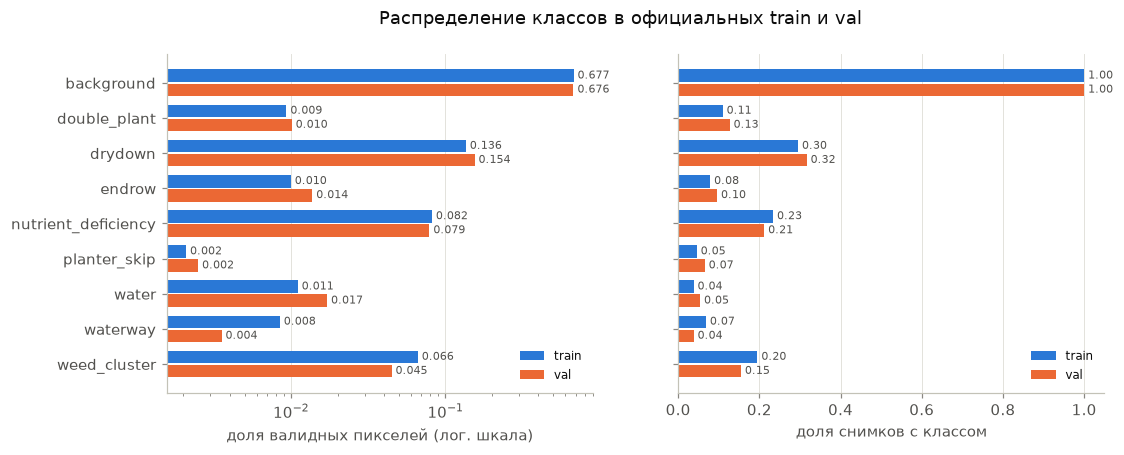

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
viz.grouped_barh(axes[0], pixel_share, value_fmt="{:.3f}", xlabel="доля валидных пикселей (лог. шкала)")
axes[0].set_xscale("log")
viz.grouped_barh(axes[1], image_share, value_fmt="{:.2f}", xlabel="доля снимков с классом")
axes[1].set_yticklabels([])
fig.suptitle("Распределение классов в официальных train и val")
viz.save(fig, "class_distribution")
plt.show()

Перекрытия меток, метки вне валидной области и класс `storm_damage` (в соревновании 2021 г. не оценивался; в работе не используется, его пиксели без других меток считаются фоном).

In [11]:
labeled_px = (stats.px_valid - stats.px_background).sum()
outside_px = stats[[f"px_outside_{c}" for c in C.PATTERN_CLASSES]].sum().sum()
inside_px = stats[[f"px_{c}" for c in C.PATTERN_CLASSES]].sum().sum()
pd.Series({
    "пикселей с ≥2 метками, % от размеченных": 100 * stats.px_overlap.sum() / labeled_px,
    "снимков с перекрытием меток": (stats.px_overlap > 0).sum(),
    "меток вне валидной области, % от всех меток": 100 * outside_px / (outside_px + inside_px),
    "storm_damage: % валидных пикселей": 100 * stats.px_storm_damage.sum() / stats.px_valid.sum(),
    "storm_damage: снимков": (stats.px_storm_damage > 0).sum(),
    "storm_damage без других меток, % валидных пикселей": 100 * stats.px_storm_damage_only.sum() / stats.px_valid.sum(),
}).round(4)

пикселей с ≥2 метками, % от размеченных                  0.3759
снимков с перекрытием меток                           2334.0000
меток вне валидной области, % от всех меток              1.1275
storm_damage: % валидных пикселей                        0.1787
storm_damage: снимков                                  445.0000
storm_damage без других меток, % валидных пикселей       0.1753
dtype: float64

Дубликаты: совпадение MD5 файла RGB внутри и между выборками.

In [12]:
dup = stats[stats.duplicated("rgb_md5", keep=False)]
pd.Series({
    "снимков, имеющих дубликат": len(dup),
    "групп дубликатов": dup.rgb_md5.nunique(),
    "групп в разных выборках": int((dup.groupby("rgb_md5").official_split.nunique() > 1).sum()),
})

снимков, имеющих дубликат    0
групп дубликатов             0
групп в разных выборках      0
dtype: int64

Яркость каналов (среднее по валидным пикселям снимка): поиск тёмных и засвеченных снимков.

,count,mean,std,min,25%,50%,75%,max
mean_R,75278.0,110.3694,33.2156,0.1195,87.3574,109.2402,132.8929,250.5567
mean_G,75278.0,111.9754,30.4964,0.1982,90.2309,109.5038,132.0159,248.1368
mean_B,75278.0,111.7322,29.4450,10.2257,90.8717,111.3970,131.1939,251.7123
mean_N,75278.0,116.7946,32.4582,0.0000,92.9747,115.2210,139.2472,238.0152


снимков со средней яркостью канала < 10: 66 | > 245: 5


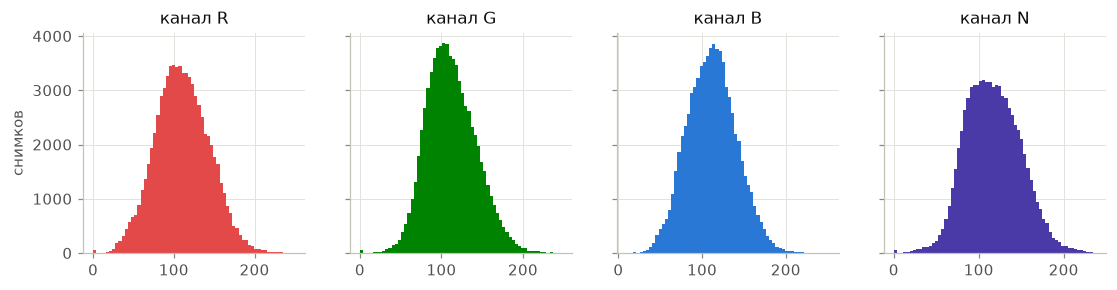

In [13]:
ch_cols = ["mean_R", "mean_G", "mean_B", "mean_N"]
display(stats[ch_cols].describe().T)
print("снимков со средней яркостью канала < 10:", int((stats[ch_cols] < 10).any(axis=1).sum()),
      "| > 245:", int((stats[ch_cols] > 245).any(axis=1).sum()))

fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), sharey=True)
for ax, col, color in zip(axes, ch_cols, [viz.SERIES[7], viz.SERIES[5], viz.SERIES[0], viz.SERIES[6]]):
    ax.hist(stats[col].dropna(), bins=64, color=color)
    ax.set_title(col.replace("mean_", "канал "))
axes[0].set_ylabel("снимков")
viz.save(fig, "brightness")
plt.show()

Дефектные снимки: минимум два из каналов R, G, NIR практически пустые (средняя яркость < 10). Разметка на них по изображению не восстанавливается; список сохраняется, исключение — в разделе 4.

дефектных снимков: 64 | по выборкам: {'train': 64} | полётов: 5


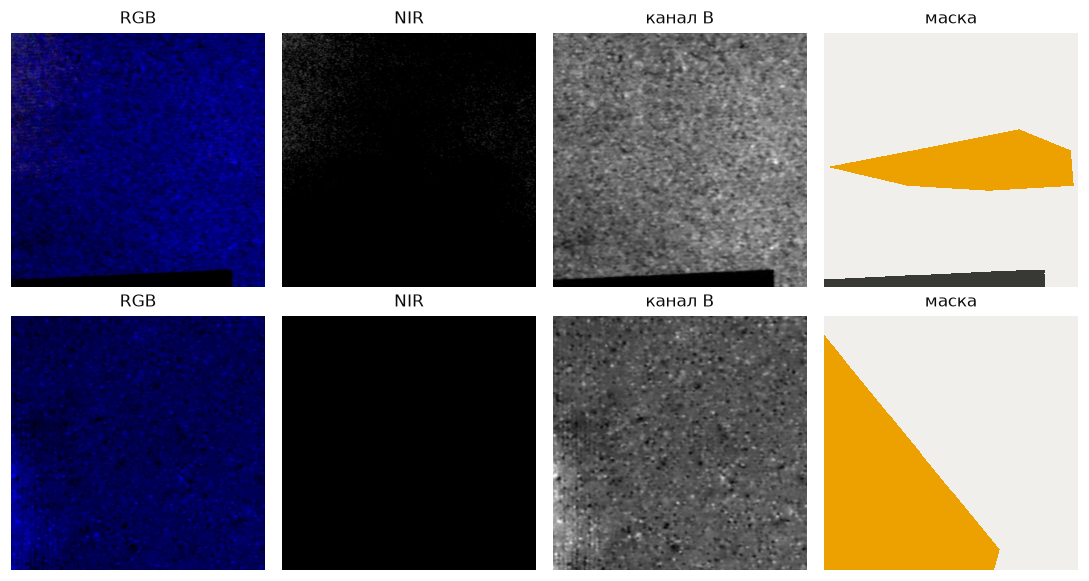

In [14]:
empty = stats[["mean_R", "mean_G", "mean_N"]] < 10
defective = stats[empty.sum(axis=1) >= 2]
defective[["id", "official_split", "flightcode", "field"] + ch_cols].to_csv(C.OUT_DIR / "defective_images.csv", index=False)
print("дефектных снимков:", len(defective), "| по выборкам:", defective.official_split.value_counts().to_dict(),
      "| полётов:", defective.flightcode.nunique())

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for row, r in zip(axes, defective.groupby("flightcode").head(1).head(2).itertuples()):
    img = data.load_image(r.official_split, r.id)
    viz.show_rgb(row[0], img)
    viz.show_nir(row[1], img)
    row[2].imshow(img[..., 2], cmap="gray")
    row[2].set_title("канал B")
    row[2].axis("off")
    viz.show_mask(row[3], viz.bitmask_to_labelmap(data.load_bitmask(r.id)), "маска")
fig.tight_layout()
viz.save(fig, "defective")
plt.show()

Пересечение полей между официальными выборками. Авторы датасета делили данные по полётам: одно поле, снятое в разные даты, может попасть и в `train`, и в `val`.

In [15]:
fields = index.groupby("official_split").field.apply(set)
shared = fields["train"] & fields["val"]
val_on_shared = index[(index.official_split == "val") & index.field.isin(shared)]
pd.Series({
    "полей в val": len(fields["val"]),
    "из них встречаются в train": len(shared),
    "снимков val на таких полях": len(val_on_shared),
    "доля снимков val": len(val_on_shared) / (index.official_split == "val").sum(),
}).round(3)

полей в val                    572.000
из них встречаются в train     242.000
снимков val на таких полях    9395.000
доля снимков val                 0.512
dtype: float64

Примеры: RGB, NIR и маска; для каждого класса — снимок, где класс занимает больше 10% валидных пикселей.

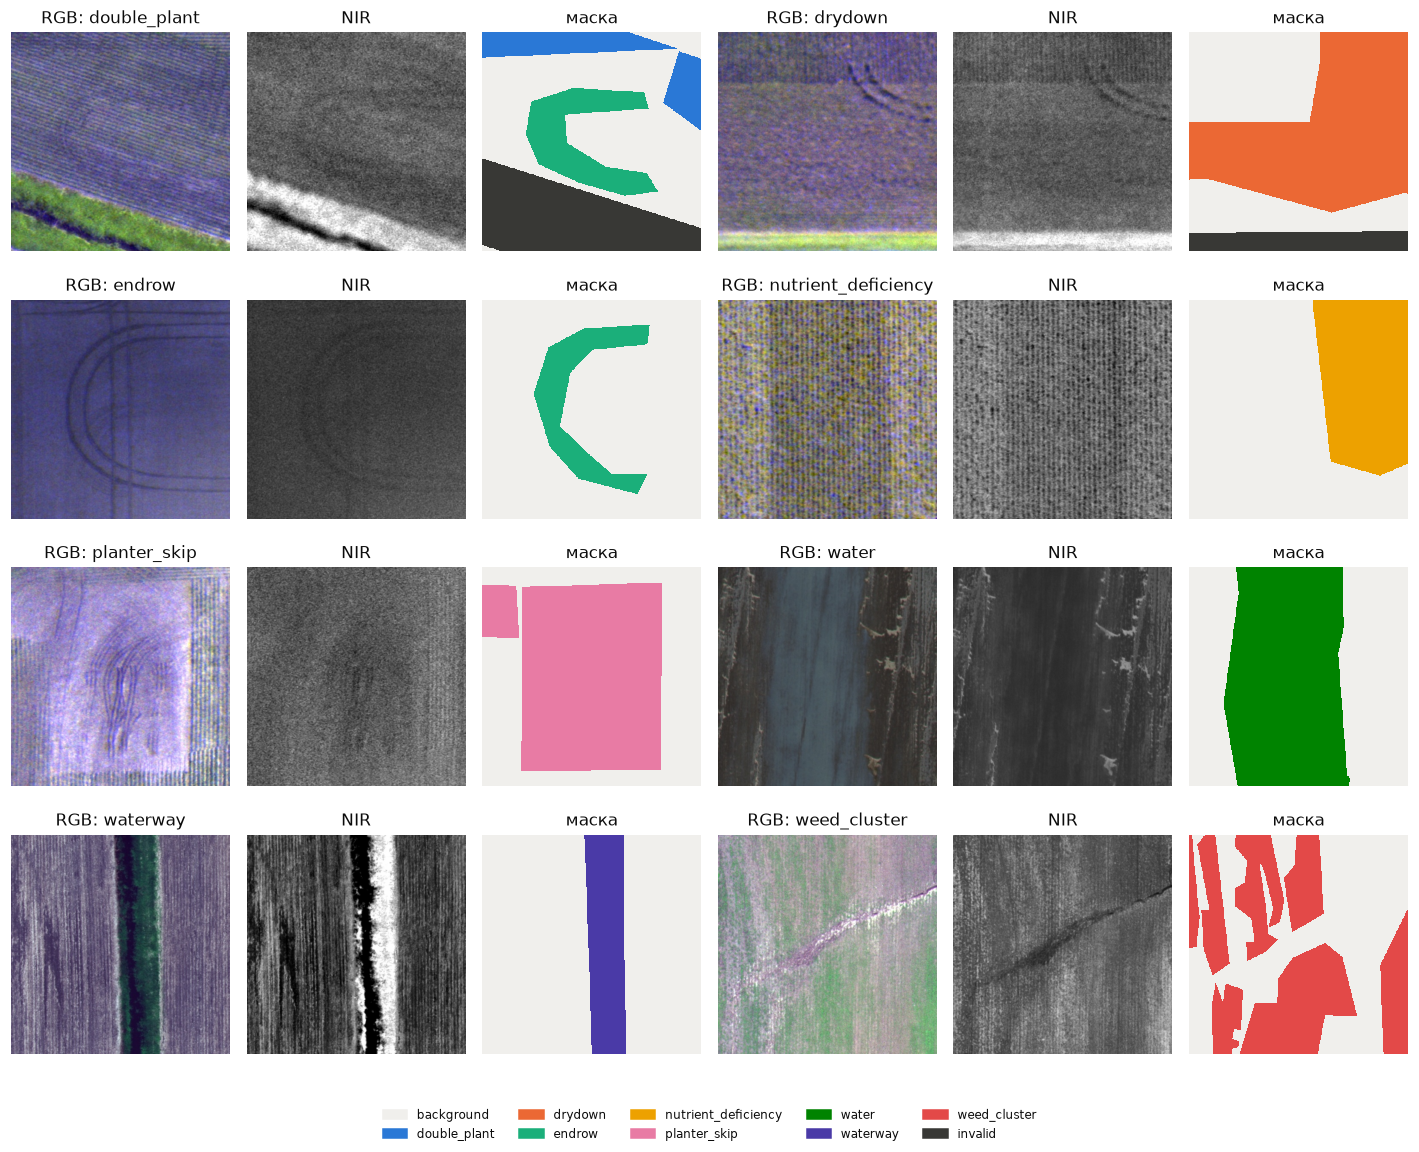

In [16]:
rng = np.random.default_rng(C.SEED)
fig, axes = plt.subplots(4, 6, figsize=(13, 10.5))
for i, cls in enumerate(C.PATTERN_CLASSES):
    cand = stats[(stats.official_split == "train") & (stats[f"px_{cls}"] > 0.1 * stats.px_valid)
                 & ~stats.id.isin(defective.id)]
    row = cand.iloc[rng.integers(len(cand))]
    img, bm = data.load_image("train", row.id), data.load_bitmask(row.id)
    ax = axes[i // 2, (i % 2) * 3:(i % 2) * 3 + 3]
    viz.show_rgb(ax[0], img, f"RGB: {cls}")
    viz.show_nir(ax[1], img)
    viz.show_mask(ax[2], viz.bitmask_to_labelmap(bm), "маска")
fig.tight_layout(rect=(0, 0.05, 1, 1), h_pad=1.5)
viz.class_legend(fig)
viz.save(fig, "examples")
plt.show()

## Разбиение

Тест — официальный `val` (разметка официального `test` закрыта; вариант выбран для сравнимости с опубликованными результатами). Валидация — 10% полей официального `train`: отбор по полям, чтобы снимки одного поля не попадали одновременно в обучение и валидацию.

In [17]:
index = data.split_by_field(index, val_frac=0.1)
F = index.groupby("split").field.apply(set)
assert not (F["train"] & F["val"])

split_info = index.groupby("split").agg(
    images=("id", "size"), flights=("flightcode", "nunique"), fields=("field", "nunique")
).loc[["train", "val", "test"]]
split_info["общих полей с train"] = [0, len(F["val"] & F["train"]), len(F["test"] & F["train"])]
index[["id", "split"]].to_csv(C.OUT_DIR / "split.csv.gz", index=False)
split_info

,images,flights,fields,общих полей с train
split,,,,
train,51281,1764,1276,0
val,5663,186,135,0
test,18334,656,572,219


## Предобработка

**Очистка данных.** Исключение дефектных снимков, найденных в разделе 2. Тест не меняется.

In [18]:
before = index.split.value_counts()
assert not index[index.split == "test"].id.isin(defective.id).any()
index = index[~index.id.isin(defective.id)]
after = index.split.value_counts()
pd.DataFrame({"до": before, "исключено": before - after, "после": after}).loc[["train", "val", "test"]]

,до,исключено,после
split,,,
train,51281,63,51218
val,5663,1,5662
test,18334,0,18334


Нормализация: среднее и СКО каналов R, G, B, NIR по валидным пикселям 2000 случайных снимков обучающей выборки.

In [19]:
mean, std = data.compute_norm_stats(index)
(C.OUT_DIR / "norm_stats.json").write_text(json.dumps({"mean": mean, "std": std}, indent=2))
pd.DataFrame({"mean": mean, "std": std}, index=["R", "G", "B", "NIR"])

,mean,std
R,0.4379,0.1647
G,0.4466,0.1541
B,0.4404,0.1556
NIR,0.4592,0.1717


Загрузчики. Аугментации только для обучения: поворот на k·90° и горизонтальное отражение (у снимков сверху нет выделенной ориентации). Цвет не меняется, чтобы сохранить соотношение каналов RGB и NIR.

In [20]:
BATCH = 16
frames = {s: index[index.split == s] for s in ["train", "val", "test"]}
loaders = {s: train.make_loader(frames[s], mean, std, BATCH, train=(s == "train"), workers=WORKERS) for s in frames}

x, bm = next(iter(loaders["train"]))
print("x:", tuple(x.shape), x.dtype, "| маска:", tuple(bm.shape), bm.dtype)
print("среднее по каналам после нормализации:", x.mean((0, 2, 3)).numpy().round(3))

x: (16, 4, 512, 512) torch.float32 | маска: (16, 512, 512) torch.int32
среднее по каналам после нормализации: [-0.081 -0.113 -0.054  0.073]


## Гипотезы

Сформулированы после анализа данных, до обучения.

1. **H1.** DPT + DINOv3 ViT-S/16 получит наибольший mIoU на тесте: при самом маленьком кодировщике (21,7 млн параметров) самообучение на 1,7 млрд изображений даёт более переносимые признаки, чем обучение с учителем на ImageNet.
2. **H2.** UPerNet + ConvNeXt-Tiny превзойдёт U-Net + ResNet-50 по mIoU: при сопоставимом размере ConvNeXt — модернизированная свёрточная архитектура с более высокой точностью на ImageNet (82,1% против 76,1% top-1).
3. **H3.** На мелкоструктурных классах `double_plant` и `planter_skip` U-Net + ResNet-50 получит больший IoU, чем DPT + DINOv3: skip-соединения U-Net передают в декодер признаки с разрешением 1/2 и 1/4, а ViT с патчем 16 работает с разрешением 1/16.
4. **H4.** Самый редкий класс `planter_skip` (0,2% пикселей) получит наименьший IoU у всех трёх моделей.

## Модели

Все модели — из `segmentation_models_pytorch`, кодировщики с предобученными весами из `timm`. Первый слой расширен до 4 каналов: веса RGB копируются, канал NIR инициализируется весами канала R, все веса слоя умножаются на 3/4. Декодер DPT — конфигурация для ViT-S из Depth Anything (каналы 48/96/192/384, слияние 64).

In [21]:
MODEL_NAMES = list(models.MODEL_SPECS)
model_info = []
for name in MODEL_NAMES:
    m = models.build_model(name, C.NUM_CLASSES)
    model_info.append({
        "модель": models.MODEL_SPECS[name]["title"],
        "кодировщик": models.MODEL_SPECS[name]["encoder"],
        "параметров, млн": models.count_params(m) / 1e6,
        "в т.ч. кодировщик, млн": models.count_params(m.encoder) / 1e6,
        "GFLOPs (512×512)": bench.count_gflops(m),
    })
    del m
model_info = pd.DataFrame(model_info, index=MODEL_NAMES)
model_info

,модель,кодировщик,"параметров, млн","в т.ч. кодировщик, млн",GFLOPs (512×512)
unet_resnet50,U-Net + ResNet-50,resnet50,32.5254,23.5112,86.0755
upernet_convnext_tiny,UPerNet + ConvNeXt-Tiny,tu-convnext_tiny.fb_in1k,37.0475,27.8201,152.8930
dpt_dinov3_vits16,DPT + DINOv3 ViT-S/16,tu-vit_small_patch16_dinov3.lvd1689m,25.6058,21.6852,62.0532


## Подбор learning rate

Короткие прогоны: 1 эпоха на фиксированных 20% обучающей выборки, оценка на фиксированных 25% валидационной. Правило выбора зафиксировано до запуска: общий lr для всех моделей — с наибольшим средним mIoU по трём моделям.

In [22]:
LRS = [3e-4, 1e-4, 3e-5]
WD = 0.01
probe_loaders = {
    "train": train.make_loader(frames["train"].sample(frac=0.2, random_state=C.SEED), mean, std, BATCH, True, WORKERS),
    "val": train.make_loader(frames["val"].sample(frac=0.25, random_state=C.SEED), mean, std, BATCH, False, WORKERS),
}
probe = []
for name in MODEL_NAMES:
    for lr in LRS:
        train.seed_everything(C.SEED)
        model = models.build_model(name, C.NUM_CLASSES)
        hist = train.train_model(model, f"lr_probe/{name}_lr{lr:g}", probe_loaders["train"], probe_loaders["val"],
                                 epochs=1, lr=lr, weight_decay=WD)
        probe.append({"model": name, "lr": lr, "val_mIoU": hist.val_mIoU.iloc[-1]})
        del model
        torch.cuda.empty_cache()
del probe_loaders

probe = pd.DataFrame(probe).pivot(index="model", columns="lr", values="val_mIoU")
probe.loc["среднее"] = probe.mean()
LR = float(probe.loc["среднее"].idxmax())
probe.to_csv(C.OUT_DIR / "lr_probe.csv")
print("выбран lr =", LR)
probe

[lr_probe/unet_resnet50_lr0.0003] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 1.8275 | val_loss 1.6279 | val_mIoU 0.1783 | 47 img/s | 3.9 min


[lr_probe/unet_resnet50_lr0.0001] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 2.0593 | val_loss 1.8151 | val_mIoU 0.1686 | 48 img/s | 3.8 min


[lr_probe/unet_resnet50_lr3e-05] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 2.5278 | val_loss 2.2923 | val_mIoU 0.1642 | 47 img/s | 3.9 min


[lr_probe/upernet_convnext_tiny_lr0.0003] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 1.4170 | val_loss 1.2447 | val_mIoU 0.3568 | 45 img/s | 4.0 min


[lr_probe/upernet_convnext_tiny_lr0.0001] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 1.4880 | val_loss 1.3047 | val_mIoU 0.3144 | 45 img/s | 4.0 min


[lr_probe/upernet_convnext_tiny_lr3e-05] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 1.7089 | val_loss 1.4641 | val_mIoU 0.2602 | 45 img/s | 4.0 min


[lr_probe/dpt_dinov3_vits16_lr0.0003] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 1.9058 | val_loss 1.5644 | val_mIoU 0.2167 | 59 img/s | 3.1 min


[lr_probe/dpt_dinov3_vits16_lr0.0001] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 1.9235 | val_loss 1.5617 | val_mIoU 0.2936 | 60 img/s | 3.1 min


[lr_probe/dpt_dinov3_vits16_lr3e-05] загружен чекпойнт после эпохи 1
epoch 1/1: train_loss 2.2716 | val_loss 1.8501 | val_mIoU 0.2813 | 60 img/s | 3.1 min
выбран lr = 0.0001


lr,3.0000e-05,1.0000e-04,3.0000e-04
model,,,
dpt_dinov3_vits16,0.2813,0.2936,0.2167
unet_resnet50,0.1642,0.1686,0.1783
upernet_convnext_tiny,0.2602,0.3144,0.3568
среднее,0.2352,0.2588,0.2506


## Обучение

Одинаковые условия для всех моделей: AdamW (weight decay 0.01), выбранный lr, батч 16, разогрев 5% шагов и косинусное затухание, смешанная точность bf16, функция потерь CE + Dice, 6 эпох. Лучшая эпоха выбирается по mIoU на валидации. Чекпойнты сохраняются после каждой эпохи; при повторном запуске обучение продолжается с последней сохранённой эпохи.

In [23]:
EPOCHS = 6
histories = {}
for name in MODEL_NAMES:
    train.seed_everything(C.SEED)
    model = models.build_model(name, C.NUM_CLASSES)
    histories[name] = train.train_model(model, name, loaders["train"], loaders["val"],
                                        epochs=EPOCHS, lr=LR, weight_decay=WD)
    del model
    torch.cuda.empty_cache()

[unet_resnet50] загружен чекпойнт после эпохи 6
epoch 1/6: train_loss 1.7260 | val_loss 1.3098 | val_mIoU 0.2794 | 49 img/s | 18.8 min
epoch 2/6: train_loss 1.2297 | val_loss 1.1402 | val_mIoU 0.3571 | 50 img/s | 18.0 min
epoch 3/6: train_loss 1.0830 | val_loss 1.1196 | val_mIoU 0.3678 | 50 img/s | 17.9 min
epoch 4/6: train_loss 0.9727 | val_loss 1.2336 | val_mIoU 0.3728 | 50 img/s | 17.8 min
epoch 5/6: train_loss 0.9006 | val_loss 1.1192 | val_mIoU 0.3870 | 50 img/s | 17.9 min
epoch 6/6: train_loss 0.8619 | val_loss 1.1479 | val_mIoU 0.3816 | 50 img/s | 17.9 min


[upernet_convnext_tiny] загружен чекпойнт после эпохи 6
epoch 1/6: train_loss 1.2415 | val_loss 1.0742 | val_mIoU 0.3928 | 48 img/s | 18.7 min
epoch 2/6: train_loss 0.8627 | val_loss 1.0061 | val_mIoU 0.4454 | 48 img/s | 18.7 min
epoch 3/6: train_loss 0.7582 | val_loss 0.9503 | val_mIoU 0.4606 | 48 img/s | 18.7 min
epoch 4/6: train_loss 0.6765 | val_loss 1.0791 | val_mIoU 0.4211 | 48 img/s | 18.8 min
epoch 5/6: train_loss 0.6224 | val_loss 1.0547 | val_mIoU 0.4294 | 48 img/s | 18.7 min
epoch 6/6: train_loss 0.5900 | val_loss 1.0852 | val_mIoU 0.4252 | 48 img/s | 18.7 min


[dpt_dinov3_vits16] загружен чекпойнт после эпохи 6
epoch 1/6: train_loss 1.4964 | val_loss 1.0602 | val_mIoU 0.4008 | 63 img/s | 14.3 min
epoch 2/6: train_loss 0.9159 | val_loss 1.0067 | val_mIoU 0.4343 | 63 img/s | 14.3 min
epoch 3/6: train_loss 0.7994 | val_loss 0.9394 | val_mIoU 0.4550 | 62 img/s | 14.4 min
epoch 4/6: train_loss 0.7151 | val_loss 0.9737 | val_mIoU 0.4585 | 63 img/s | 14.3 min
epoch 5/6: train_loss 0.6549 | val_loss 0.9618 | val_mIoU 0.4646 | 63 img/s | 14.3 min
epoch 6/6: train_loss 0.6213 | val_loss 0.9771 | val_mIoU 0.4607 | 63 img/s | 14.3 min


Кривые обучения.

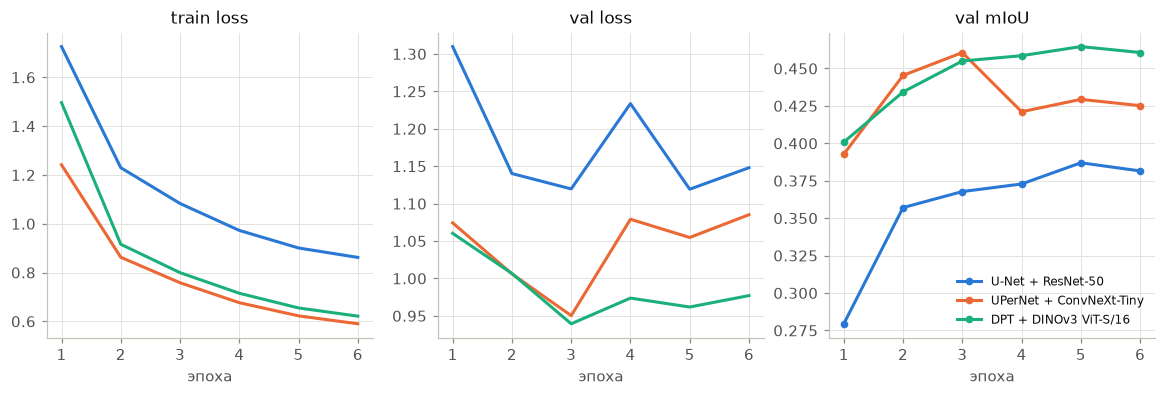

,лучшая эпоха,val mIoU,мин/эпоха,изобр./с (обучение),"пик памяти GPU, ГБ"
U-Net + ResNet-50,5,0.3870,18.0418,49.8887,6.9299
UPerNet + ConvNeXt-Tiny,3,0.4606,18.7368,47.8459,9.7882
DPT + DINOv3 ViT-S/16,5,0.4646,14.3412,62.5258,5.9556


In [24]:
titles = {n: models.MODEL_SPECS[n]["title"] for n in MODEL_NAMES}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for i, name in enumerate(MODEL_NAMES):
    h = histories[name]
    axes[0].plot(h.epoch, h.train_loss, color=viz.SERIES[i], label=titles[name])
    axes[1].plot(h.epoch, h.val_loss, color=viz.SERIES[i], label=titles[name])
    axes[2].plot(h.epoch, h.val_mIoU, color=viz.SERIES[i], marker="o", markersize=4, label=titles[name])
for ax, t in zip(axes, ["train loss", "val loss", "val mIoU"]):
    ax.set_title(t)
    ax.set_xlabel("эпоха")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[2].legend(fontsize=8)
viz.save(fig, "learning_curves")
plt.show()

pd.DataFrame({
    titles[n]: {
        "лучшая эпоха": int(h.val_mIoU.idxmax() + 1),
        "val mIoU": h.val_mIoU.max(),
        "мин/эпоха": h.epoch_time_s.mean() / 60,
        "изобр./с (обучение)": h.imgs_per_s.mean(),
        "пик памяти GPU, ГБ": h.peak_mem_gb.max(),
    } for n, h in histories.items()
}).T.astype({"лучшая эпоха": int})

## Оценка на тесте

Лучший чекпойнт каждой модели на тестовой выборке (официальный `val`). Для пикселей с несколькими метками предсказание любой из них считается верным (правило Agriculture-Vision). Метрики считаются по матрице ошибок, накопленной по всей выборке. Тест оценивается двумя частями — снимки с полей, которые есть в обучающей выборке (снятые в другие даты), и с новых полей; матрицы частей суммируются в общую.

In [25]:
train_fields = set(frames["train"].field)
seen = frames["test"].field.isin(train_fields)
test_parts = {"поля из train": frames["test"][seen], "новые поля": frames["test"][~seen]}
part_loaders = {k: train.make_loader(f, mean, std, BATCH, False, WORKERS) for k, f in test_parts.items()}
print("снимков:", {k: len(f) for k, f in test_parts.items()})

test_summary, per_class, cms, by_part = {}, {}, {}, {}
for name in MODEL_NAMES:
    model = train.load_best(models.build_model(name, C.NUM_CLASSES, pretrained=False), name)
    part_cms = {k: train.evaluate(model, loader)[2] for k, loader in part_loaders.items()}
    cms[name] = sum(part_cms.values())
    test_summary[titles[name]], per_class[titles[name]] = metrics.scores_from_confusion(cms[name])
    by_part[titles[name]] = {k: metrics.scores_from_confusion(cm)[0]["mIoU"] for k, cm in part_cms.items()}
    del model
    torch.cuda.empty_cache()

test_summary = pd.DataFrame(test_summary).T
test_summary.to_csv(C.OUT_DIR / "test_metrics.csv")
test_summary

снимков: {'поля из train': 8311, 'новые поля': 10023}


,mIoU,mDice,PixelAcc
U-Net + ResNet-50,0.4233,0.5740,0.7621
UPerNet + ConvNeXt-Tiny,0.4679,0.6194,0.7832
DPT + DINOv3 ViT-S/16,0.5065,0.6567,0.8071


mIoU отдельно для снимков с полей из обучающей выборки и с новых полей: насколько пересечение полей в официальном разбиении завышает результат.

In [26]:
by_part = pd.DataFrame(by_part).T.add_prefix("mIoU: ")
by_part.insert(0, "mIoU: весь тест", test_summary.mIoU)
by_part.to_csv(C.OUT_DIR / "test_by_fields.csv")
by_part

,mIoU: весь тест,mIoU: поля из train,mIoU: новые поля
U-Net + ResNet-50,0.4233,0.3947,0.4275
UPerNet + ConvNeXt-Tiny,0.4679,0.4422,0.4723
DPT + DINOv3 ViT-S/16,0.5065,0.4874,0.5082


IoU и Dice по классам.

IoU                          \
                    U-Net + ResNet-50 UPerNet + ConvNeXt-Tiny   
background                     0.7117                  0.7352   
double_plant                   0.3035                  0.3602   
drydown                        0.5499                  0.5739   
endrow                         0.2121                  0.2466   
nutrient_deficiency            0.3686                  0.3826   
planter_skip                   0.3664                  0.4407   
water                          0.7127                  0.7701   
waterway                       0.3353                  0.3905   
weed_cluster                   0.2497                  0.3117   

                                                       Dice  \
                    DPT + DINOv3 ViT-S/16 U-Net + ResNet-50   
background                         0.7608            0.8315   
double_plant                       0.3855            0.4657   
drydown                            0.5909            0.7096   
endrow                             0.3046            0.3499   
nutrient_deficiency                0.4692            0.5387   
planter_skip                       0.4361            0.5363   
water                              0.8129            0.8322   
waterway                           0.4549            0.5023   
weed_cluster                       0.3435            0.3996   

                                                                   
                    UPerNet + ConvNeXt-Tiny DPT + DINOv3 ViT-S/16  
background                           0.8474                0.8641  
double_plant                         0.5297                0.5565  
drydown                              0.7293                0.7428  
endrow                               0.3956                0.4669  
nutrient_deficiency                  0.5534                0.6387  
planter_skip                         0.6118                0.6073  
water                                0.8701                0.8968  
waterway                             0.5617                0.6253  
weed_cluster                         0.4753                0.5114

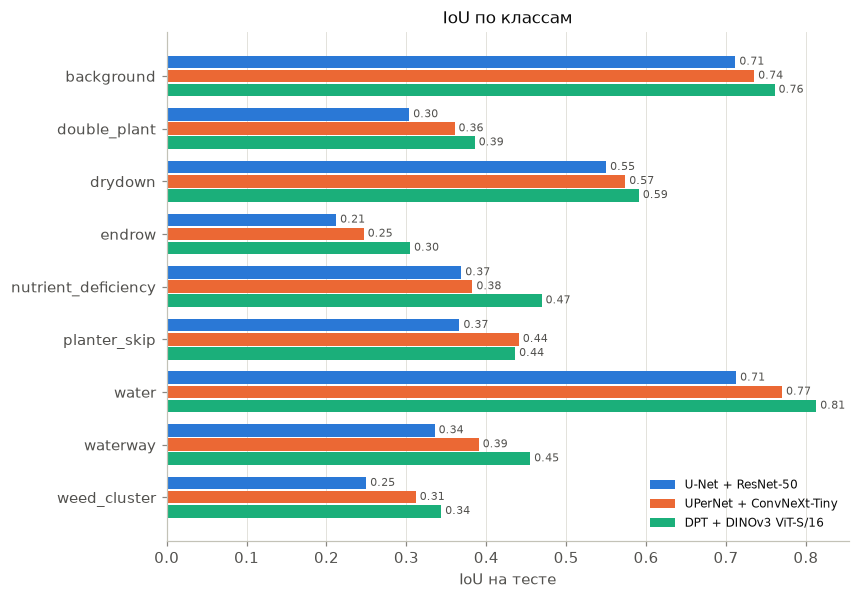

In [27]:
iou = pd.DataFrame({m: pc.IoU for m, pc in per_class.items()})
dice = pd.DataFrame({m: pc.Dice for m, pc in per_class.items()})
pd.concat({"IoU": iou, "Dice": dice}, axis=1).to_csv(C.OUT_DIR / "test_per_class.csv")
display(pd.concat({"IoU": iou, "Dice": dice}, axis=1))

fig, ax = plt.subplots(figsize=(8, 6))
viz.grouped_barh(ax, iou, value_fmt="{:.2f}", xlabel="IoU на тесте")
ax.set_title("IoU по классам")
viz.save(fig, "per_class_iou")
plt.show()

Нормированные матрицы ошибок (строка — истинный класс, доля пикселей).

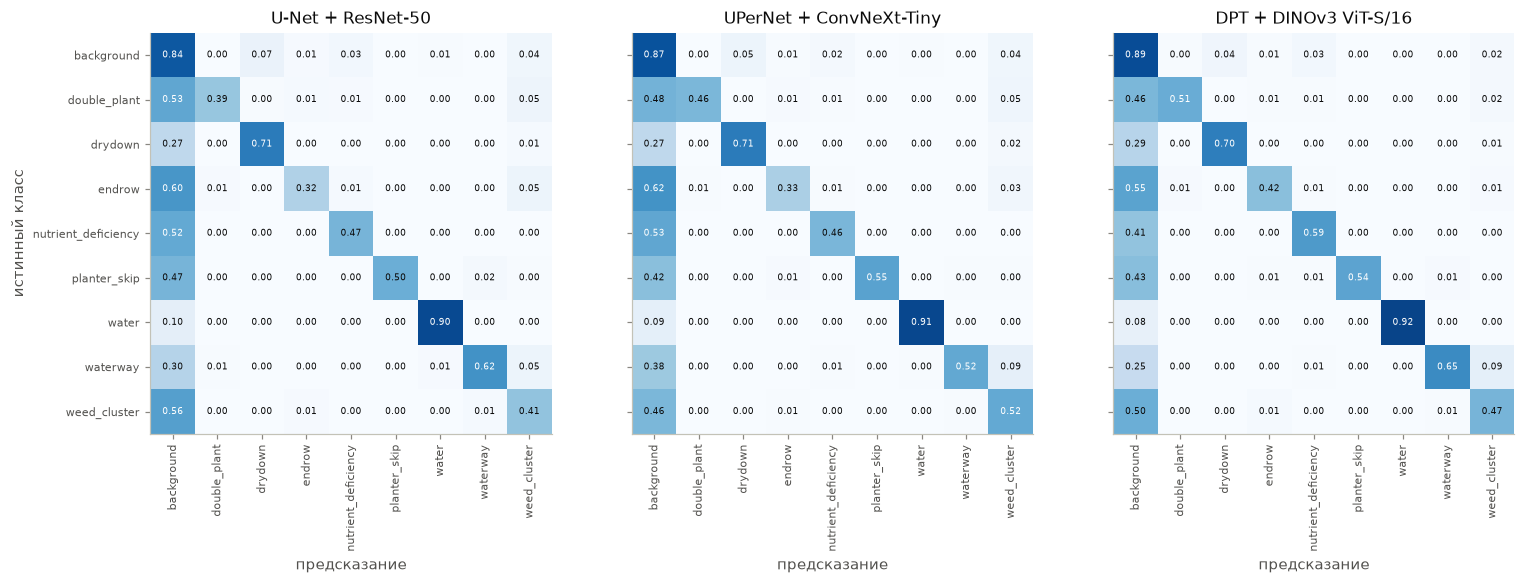

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axes, MODEL_NAMES):
    cm = cms[name].double()
    cmn = (cm / cm.sum(1, keepdim=True)).numpy()
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(C.CLASSES)):
        for j in range(len(C.CLASSES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if cmn[i, j] > 0.5 else viz.INK)
    ax.set_xticks(range(len(C.CLASSES)), C.CLASSES, rotation=90, fontsize=7)
    ax.set_yticks(range(len(C.CLASSES)), C.CLASSES if ax is axes[0] else [], fontsize=7)
    ax.grid(False)
    ax.set_title(titles[name])
    ax.set_xlabel("предсказание")
axes[0].set_ylabel("истинный класс")
viz.save(fig, "confusion_matrices")
plt.show()

## Производительность

Задержка инференса одного снимка 512×512 (медиана по запускам): GPU в bf16, CPU в fp32 с явно заданным числом потоков. Пропускная способность GPU — батч 16.

In [29]:
print("потоков CPU:", bench.CPU_THREADS)
perf = []
for name in MODEL_NAMES:
    m = models.build_model(name, C.NUM_CLASSES, pretrained=False)
    gpu1, _ = bench.latency_ms(m, "cuda", batch_size=1)
    gpu16, _ = bench.latency_ms(m, "cuda", batch_size=16, iters=20)
    cpu1, _ = bench.latency_ms(m, "cpu", batch_size=1, iters=10, warmup=2)
    perf.append({
        "параметров, млн": model_info.loc[name, "параметров, млн"],
        "GFLOPs": model_info.loc[name, "GFLOPs (512×512)"],
        "GPU, мс/снимок (батч 1)": gpu1,
        "GPU, снимков/с (батч 16)": 16 / gpu16 * 1000,
        "CPU, мс/снимок": cpu1,
        "обучение, мин/эпоха": histories[name].epoch_time_s.mean() / 60,
        "пик памяти GPU при обучении, ГБ": histories[name].peak_mem_gb.max(),
    })
    del m
perf = pd.DataFrame(perf, index=[titles[n] for n in MODEL_NAMES])
perf.to_csv(C.OUT_DIR / "performance.csv")
perf

потоков CPU: 12


,"параметров, млн",GFLOPs,"GPU, мс/снимок (батч 1)","GPU, снимков/с (батч 16)","CPU, мс/снимок","обучение, мин/эпоха","пик памяти GPU при обучении, ГБ"
U-Net + ResNet-50,32.5254,86.0755,9.6719,165.3302,200.7311,18.0418,6.9299
UPerNet + ConvNeXt-Tiny,37.0475,152.8930,11.4056,143.0778,291.1041,18.7368,9.7882
DPT + DINOv3 ViT-S/16,25.6058,62.0532,15.2835,215.4920,175.5739,14.3412,5.9556


## Примеры предсказаний

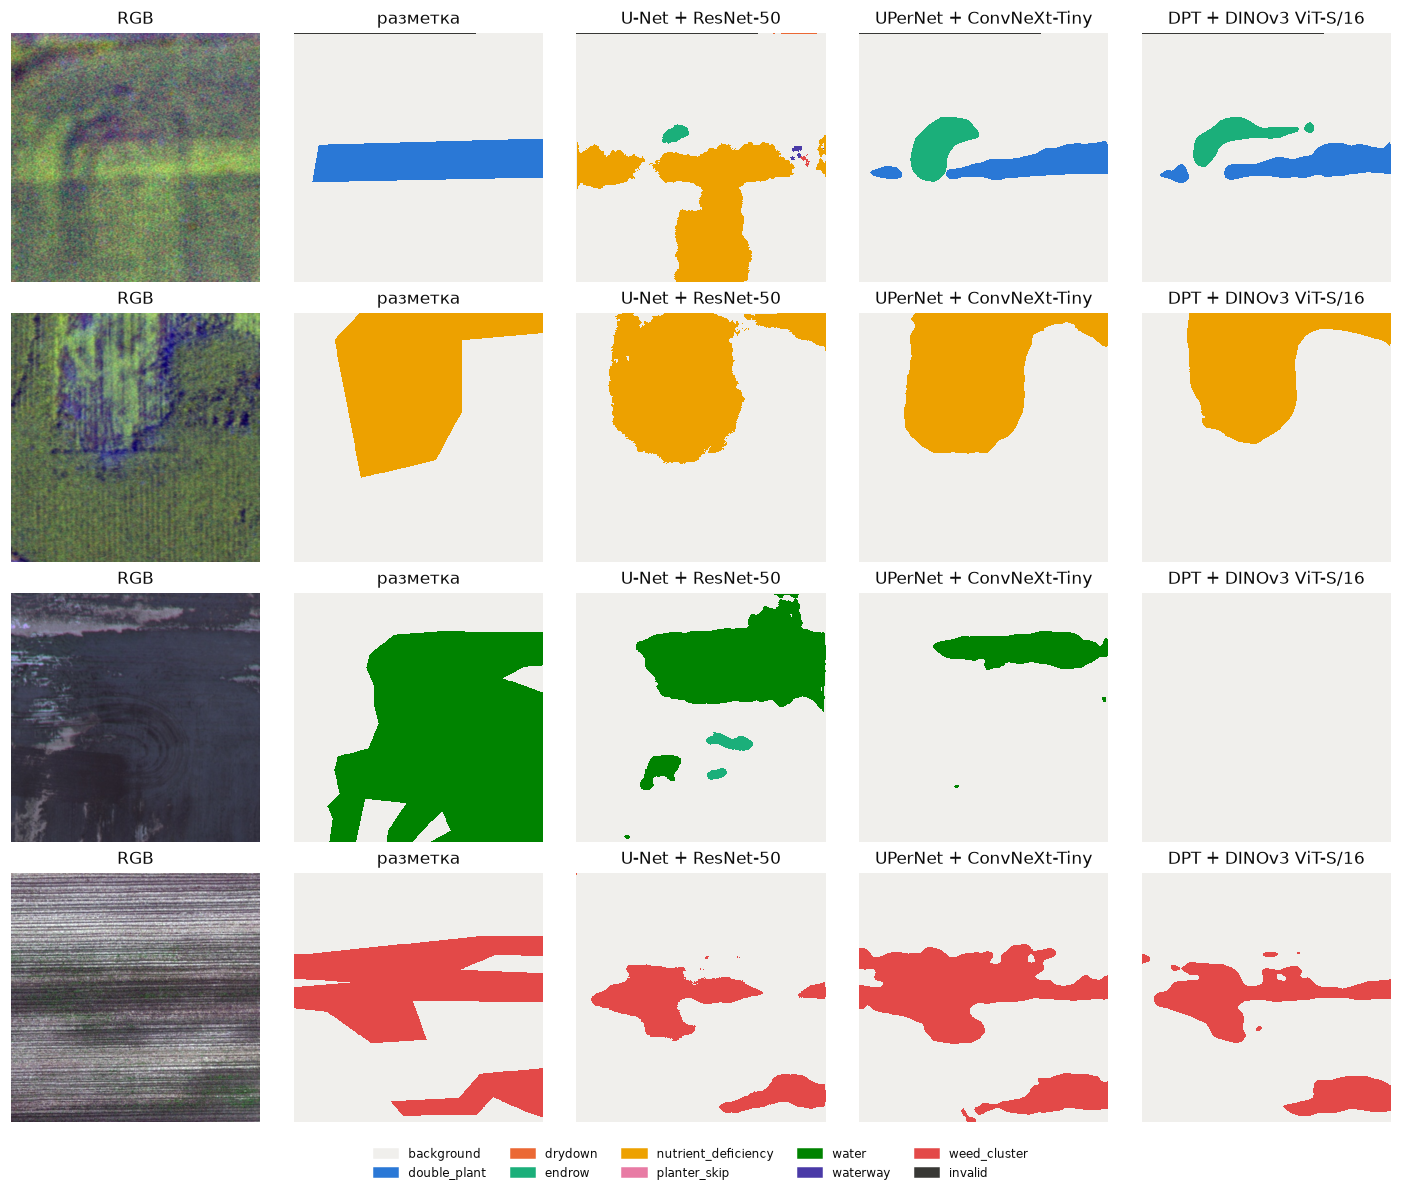

In [30]:
test_stats = stats[stats.id.isin(index[index.split == "test"].id)]
picks = [test_stats[test_stats[f"px_{c}"] > 0.1 * test_stats.px_valid].id.sample(1, random_state=C.SEED).item()
         for c in ["double_plant", "nutrient_deficiency", "water", "weed_cluster"]]
fig, axes = plt.subplots(len(picks), 5, figsize=(13, 2.7 * len(picks)))
nets = {n: train.load_best(models.build_model(n, C.NUM_CLASSES, pretrained=False), n) for n in MODEL_NAMES}
for row, image_id in zip(axes, picks):
    img, bm = data.load_image("val", image_id), data.load_bitmask(image_id)
    x = torch.from_numpy(((img / 255 - np.array(mean)) / np.array(std)).transpose(2, 0, 1)).float()[None].to(DEVICE)
    viz.show_rgb(row[0], img)
    viz.show_mask(row[1], viz.bitmask_to_labelmap(bm), "разметка")
    invalid = (bm & C.INVALID_BIT) != 0
    for ax, name in zip(row[2:], MODEL_NAMES):
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
            pred = nets[name](x).argmax(1)[0].cpu().numpy().astype(np.uint8)
        pred[invalid] = viz.INVALID_LABEL
        viz.show_mask(ax, pred, titles[name])
del nets
torch.cuda.empty_cache()
fig.tight_layout(rect=(0, 0.04, 1, 1))
viz.class_legend(fig)
viz.save(fig, "predictions")
plt.show()

## Сводная таблица

In [31]:
summary = pd.concat([test_summary, perf], axis=1)
summary.to_csv(C.OUT_DIR / "summary.csv")
summary.T

,U-Net + ResNet-50,UPerNet + ConvNeXt-Tiny,DPT + DINOv3 ViT-S/16
mIoU,0.4233,0.4679,0.5065
mDice,0.5740,0.6194,0.6567
PixelAcc,0.7621,0.7832,0.8071
"параметров, млн",32.5254,37.0475,25.6058
GFLOPs,86.0755,152.8930,62.0532
"GPU, мс/снимок (батч 1)",9.6719,11.4056,15.2835
"GPU, снимков/с (батч 16)",165.3302,143.0778,215.4920
"CPU, мс/снимок",200.7311,291.1041,175.5739
"обучение, мин/эпоха",18.0418,18.7368,14.3412
"пик памяти GPU при обучении, ГБ",6.9299,9.7882,5.9556
